#### Results. Sections #2 and #3
##### Malignant state transitions do not follow developmental directions - Developmental geometry explains malignant state positions but not malignant state variation


>Libraries

In [1]:
import os,json
import numpy as np
import pandas as pd   # dataframes
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from pprint import pprint

import scanpy as sc

import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from itertools import combinations

from scipy.stats import gaussian_kde
from scipy.stats import ttest_ind

import torch
from transformers import BertForMaskedLM

>Required functions

In [2]:
def centroid(X):
    return X.mean(axis=0) #axis 0: down to rows

def compute_centroids(X, labels):
    return {l: X[labels == l].mean(axis=0) for l in np.unique(labels)}

def centroid_value(X, labels, value):
    return X[labels == value].mean(axis=0)

def unit(v):
    n = np.linalg.norm(v)
    return v / (n + 1e-12)

def angle_deg(v1, v2):
    cs = np.dot(v1, v2) / ((np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-12)
    cs = np.clip(cs, -1, 1)
    return np.degrees(np.arccos(cs))

def branch_coordinates(X, c_root, c_terminal):
    # .. normalized the branch direction
    u = unit(c_terminal - c_root)
    # .. total branch length
    L = np.linalg.norm(c_terminal - c_root)
    
    # .. position of each cell with respect to the root
    delta = X - c_root
    # .. longitudinal coordinate along the branch
    t = delta @ u
    
    # .. project on the branch axis
    proj = np.outer(t, u)
    # .. deviation from the brancj
    d_perp = np.linalg.norm(delta - proj, axis=1)
    
    return t, d_perp, L, u

def cos_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)



>Learned model

In [3]:
# adjust you own path
commonpath = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/"
saved_dir = os.path.join(commonpath,"models/bert_dev_learned/")

In [4]:
# loads a pretrained BERT model for masked language modeling
# config.json defines the model architecture and settings
# model.safetensors contains the trained weights
model = BertForMaskedLM.from_pretrained(saved_dir)

meta_path = os.path.join(saved_dir, "vocab_meta.json")
with open(meta_path) as f:
    meta = json.load(f)

# Meta is a dictionary with the following keys
print('keys of meta dictionary -> ',meta.keys())

required = ["gene2id","PAD_ID","CLS_ID","SEP_ID","MASK_ID","DEV_DOM_ID","CANCER_DOM_ID","vocab_size"]
missing = [k for k in required if k not in meta]
assert not missing, f"vocab_meta.json missing keys: {missing}"

# unpacking the dictionary into variables.
gene2id       = meta["gene2id"]
PAD_ID        = meta["PAD_ID"]
CLS_ID        = meta["CLS_ID"]
SEP_ID        = meta["SEP_ID"]
MASK_ID       = meta["MASK_ID"]
DEV_DOM_ID    = meta["DEV_DOM_ID"]
CANCER_DOM_ID = meta["CANCER_DOM_ID"]
vocab_size    = meta["vocab_size"]

# Sanity checks (fail fast)
assert model.config.vocab_size == vocab_size, (
    f"Model vocab_size ({model.config.vocab_size}) != meta vocab_size ({vocab_size}). "
    "You likely loaded mismatched checkpoint + vocab."
)

# Ensure special IDs are in range and distinct (no two special tokens share the same ID)
specials = [PAD_ID, CLS_ID, SEP_ID, MASK_ID, DEV_DOM_ID, CANCER_DOM_ID]
assert len(set(specials)) == len(specials), "Some special token IDs collide."
assert all(0 <= x < vocab_size for x in specials), "A special token ID is out of vocab range."

keys of meta dictionary ->  dict_keys(['gene2id', 'PAD_ID', 'CLS_ID', 'SEP_ID', 'MASK_ID', 'DEV_DOM_ID', 'CANCER_DOM_ID', 'vocab_size'])


In [5]:
pprint(model.config.to_dict())

{'_name_or_path': '/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/models/bert_dev_learned/',
 'add_cross_attention': False,
 'architectures': ['BertForMaskedLM'],
 'attention_probs_dropout_prob': 0.1,
 'bad_words_ids': None,
 'begin_suppress_tokens': None,
 'bos_token_id': None,
 'chunk_size_feed_forward': 0,
 'classifier_dropout': None,
 'cross_attention_hidden_size': None,
 'decoder_start_token_id': None,
 'diversity_penalty': 0.0,
 'do_sample': False,
 'dtype': 'float32',
 'early_stopping': False,
 'encoder_no_repeat_ngram_size': 0,
 'eos_token_id': None,
 'exponential_decay_length_penalty': None,
 'finetuning_task': None,
 'forced_bos_token_id': None,
 'forced_eos_token_id': None,
 'hidden_act': 'gelu',
 'hidden_dropout_prob': 0.1,
 'hidden_size': 256,
 'id2label': {0: 'LABEL_0', 1: 'LABEL_1'},
 'initializer_range': 0.02,
 'intermediate_size': 512,
 'is_decoder': False,
 'is_encoder_decoder': False,
 'label2id': {'LABEL_0': 0, 'LABEL_1': 1},
 'layer_norm_eps': 1e-12,
 'l

In [6]:
print("vocab_size:", model.config.vocab_size)
print("number_gen:", len(gene2id))

vocab_size: 15382
number_gen: 15376


In [7]:
X_tokens_eval = np.load(os.path.join(saved_dir, "X_tokens.npy"))
X_attn_eval   = np.load(os.path.join(saved_dir, "X_attn.npy"))
domain_eval   = np.load(os.path.join(saved_dir, "domain.npy"))

In [8]:
# For each cell, tokens are: [DOM] + [CLS] + K genes + [SEP]; K = 128
print(X_tokens_eval.shape)
print(X_attn_eval.shape)
print(domain_eval.shape)

(62891, 131)
(62891, 131)
(62891,)


>Define CLS embeddings

This function produces one vector per cell that summarizes the **entire** cell’s tokenized gene-expression sequence.\
This summary vector is the CLS *embedding*.

**Why CLS?**
- BERT uses the CLS token to store a compressed representation of the whole input sequence.
- We exploit this to get a single vector representing each cell.

In [9]:
# This disables gradient tracking.You’re doing inference, not training. Saves memory
@torch.no_grad()

def cls_embeddings(model, Xt, At, batch_size=16):
    """
    Compute CLS embeddings for a set of tokenized cells.

    Xt: numpy array of shape (N, L) with token IDs
    At: numpy array of shape (N, L) with attention masks
    batch_size: how many cells to process at once (for memory reasons)

    Returns:
      CLS: numpy array of shape (N, H)
           where H = hidden size of the BERT model.
           Each row is the CLS embedding for one cell.
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    # Why eval() matters: Disables dropout. Makes outputs deterministic
    # Dropout. During training, the model randomly “ignores” some neurons each time it processes input.
    model.eval() 

    embs = []

    N = Xt.shape[0]
    for i in range(0, N, batch_size):
        # Take a minibatch of cells, B
        x_batch = Xt[i:i+batch_size]
        a_batch = At[i:i+batch_size]

        # Convert to torch tensors on the right device
        x = torch.as_tensor(x_batch, dtype=torch.long, device=device)  # (B, L)
        a = torch.as_tensor(a_batch, dtype=torch.long, device=device)  # (B, L)

        # Run only the BERT encoder
        out = model.bert(input_ids=x,attention_mask=a,output_hidden_states=False,return_dict=True)

        # out.last_hidden_state: (B, L, H)
        # Your sequence is [DOM], [CLS], genes..., [SEP],
        # so CLS is at position index 1.
        cls_batch = out.last_hidden_state[:, 1, :]   # (B, H)

        # Move to CPU and store
        embs.append(cls_batch.cpu())

    # Concatenate all batches -> (N, H)
    CLS = torch.cat(embs, dim=0).numpy()
    return CLS


# Compute CLS embeddings for eval set ----------
CLS = cls_embeddings(model, X_tokens_eval, X_attn_eval, batch_size=16)  # (N, H)

# domain_eval: 0 = development, 1 = cancer
is_dev = (domain_eval == 0)
is_can = (domain_eval == 1)

In [10]:
# .. specific of each domain
X_dev = CLS[is_dev]   # (n_dev, H)
X_can = CLS[is_can]   # (n_can, H)
del CLS

print("X_dev:", X_dev.shape)
print("X_can:", X_can.shape)

X_dev: (34760, 256)
X_can: (28131, 256)


>Lineage reference frame

Cell annotations

In [11]:
# Paths (must match your previous save locations)
in_dev    = os.path.join(commonpath, "development/A_dev_aligned.h5ad")
A_dev_aln    = sc.read_h5ad(in_dev)

In [12]:
print(A_dev_aln.obs['major_trajectory'].unique())
print("")
print(A_dev_aln.obs['celltype_update'].unique())
print("")
print(A_dev_aln.obs['endo_category'].unique())
print("")
print(A_dev_aln.obs['dev_state_pancreas'].unique())

['Epithelial_cells', 'Intestine', 'Hepatocytes', 'Lung_and_airway', 'Eye_and_other']
Categories (5, object): ['Epithelial_cells', 'Eye_and_other', 'Hepatocytes', 'Intestine', 'Lung_and_airway']

['Pancreatic acinar cells', 'Biliary epithelial cells', 'Foregut epithelial cells', 'Thymic epithelial cells', 'Thyroid gland cells', ..., 'Lung cells (Eln+)', 'Alveolar Type 1 cells', 'Airway goblet cells', 'Lung progenitor cells', 'Pancreatic islets']
Length: 19
Categories (19, object): ['Airway club cells', 'Airway goblet cells', 'Alveolar Type 1 cells', 'Alveolar Type 2 cells', ..., 'Pancreatic islets', 'Parathyroid epithelial cells', 'Thymic epithelial cells', 'Thyroid gland cells']

['pancreas_acinar', 'biliary', 'pancreas_ductal_proxy', 'foregut_other', 'gut_epithelium_distal', 'gut_epithelium_proximal_or_mixed', 'liver_hepatocyte', 'lung_airway', 'lung_progenitor', 'pancreas_islet']
Categories (10, object): ['biliary', 'foregut_other', 'gut_epithelium_distal', 'gut_epithelium_proximal_o

Clean developmental labels - **lineage referenced frames**

In [13]:
def map_state(x):
    if x == "foregut_other":
        return "foregut"
    elif x == "pancreas_ductal_proxy":
        return "ductal"
    elif x == "pancreas_acinar":
        return "acinar"
    elif x == "biliary":
        return "biliary"
    elif x == "pancreas_islet":
        return "islet"
    else:
        return "other"

A_dev_aln.obs["dev_clean"] =A_dev_aln.obs["endo_category"].map(map_state)

In [14]:
A_dev_aln.obs["dev_clean"].value_counts()

dev_clean
other      20000
ductal      4000
foregut     3948
acinar      3747
biliary     1742
islet       1323
Name: count, dtype: int64

In [15]:
print("total number cells: ",4000+3948+3747+1742)

total number cells:  13437


Cancer

In [16]:
# Paths (must match your previous save locations)
in_cancer = os.path.join(commonpath, "pdac/A_cancer_aligned.h5ad")
A_cancer_aln = sc.read_h5ad(in_cancer)

---
---

>**Developmental** PCA

In [17]:
# Center using DEV mean
mu = X_dev.mean(axis=0)  # column-wise mean
Xd = X_dev - mu
Xc = X_can - mu

In [18]:
# .. developmental PCA
pca = PCA(n_components=75)  # or enough to cover ~90% variance
Xd_pca = pca.fit_transform(Xd)
# .. basis
basis = pca.components_.T   # shape: embedding_dim x k
print('basis shape:',basis.shape)

print("DEV variance explained by first 75 PCs:", 
      pca.explained_variance_ratio_.sum())
print('PCA projection dims:',Xd_pca.shape)
print('')

pca_24 = PCA(n_components=24)  # or enough to cover ~90% variance
Xd_pca_24 = pca_24.fit_transform(Xd)

print("DEV variance explained by first 24 PCs:", 
      pca_24.explained_variance_ratio_.sum())
print('PCA projection dims:',Xd_pca_24.shape)

basis shape: (256, 75)
DEV variance explained by first 75 PCs: 0.981794
PCA projection dims: (34760, 75)

DEV variance explained by first 24 PCs: 0.755326
PCA projection dims: (34760, 24)


*recall the basis **B** use*

In [19]:
Xd_pca_B = Xd @ basis # alternative to pca.fit_transform(Xd)
print('PCA projection dims, B-based:',Xd_pca_B.shape)
print('PCA by fit or B; differences? ', np.max(np.abs(Xd_pca - Xd_pca_B)))

PCA projection dims, B-based: (34760, 75)
PCA by fit or B; differences?  3.0994415e-06


**PC developmental subspace masked by the specific lineages**

In [20]:
# .. subset data
mask = A_dev_aln.obs["dev_clean"].isin(["foregut", "ductal", "acinar", "biliary"])
labels_dev = A_dev_aln.obs["dev_clean"][mask].values

# ..
Xd_pca_sub = Xd_pca[mask]

print(Xd_pca_sub.shape)
print(labels_dev.shape)
print(np.unique(labels_dev, return_counts=True))

(13437, 75)
(13437,)
(array(['acinar', 'biliary', 'ductal', 'foregut'], dtype=object), array([3747, 1742, 4000, 3948]))


>**Cancer** on developmental subspace

In [21]:
# .. cancer on developmental PCA
Xc_pca = pca.transform(Xc)

**Cancer Reconstruction**

In [22]:
# Xd_pca = Xd @ basis
# Xc_pca = Xc @ basis

X_dev_recon = Xd_pca @ basis.T
X_can_recon = Xc_pca @ basis.T

X_dev_resid = Xd - X_dev_recon
X_can_resid = Xc - X_can_recon

In [23]:
print('dim reconstruction dev:', X_dev_recon.shape)
print('dim reconstruction can:', X_can_recon.shape)

dim reconstruction dev: (34760, 256)
dim reconstruction can: (28131, 256)


In [24]:
dev_proj_norm2 = np.sum(X_dev_recon**2, axis=1) # axis 1: down to columns
dev_resid_norm2 = np.sum(X_dev_resid**2, axis=1)

can_proj_norm2 = np.sum(X_can_recon**2, axis=1)
can_resid_norm2 = np.sum(X_can_resid**2, axis=1)

dev_frac_explained = dev_proj_norm2 / (dev_proj_norm2 + dev_resid_norm2 + 1e-12)
can_frac_explained = can_proj_norm2 / (can_proj_norm2 + can_resid_norm2 + 1e-12)

**Plots** - *distribution of fraction explained:* substantial nondevelopmental novelty

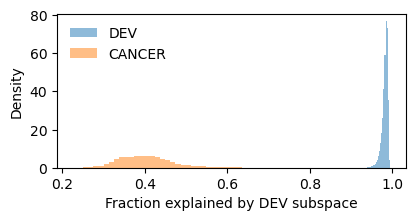

In [25]:
plt.figure(figsize=(4.5,2)) #(related to Fig.1C)
plt.hist(dev_frac_explained, bins=50, alpha=0.5, density=True, label="DEV")
plt.hist(can_frac_explained, bins=50, alpha=0.5, density=True, label="CANCER")
plt.xlabel("Fraction explained by DEV subspace")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.show()

*By cancer state*

In [26]:
df_subspace = pd.DataFrame({"frac_explained": can_frac_explained,"resid_norm": np.sqrt(can_resid_norm2)})

if "state" in A_cancer_aln.obs.columns:
    df_subspace["state"] = A_cancer_aln.obs["state"].values
elif "cancer_state" in A_cancer_aln.obs.columns:
    df_subspace["state"] = A_cancer_aln.obs["cancer_state"].values
elif "cluster" in A_cancer_aln.obs.columns:
    df_subspace["state"] = A_cancer_aln.obs["cluster"].values

df_subspace.groupby("state", observed=True)[["frac_explained", "resid_norm"]].median().sort_values("frac_explained")

,frac_explained,resid_norm
state,,
ductal,0.385996,11.873837
transitional,0.400921,11.716490
malignant_ductal,0.401083,11.817935


>Core geometric objects

In [27]:
# centroids as a dictionary
states = ["foregut", "ductal", "acinar", "biliary"]
centroids = {
    s: centroid(Xd_pca_sub[labels_dev == s])
    for s in states
}

In [28]:
for s in ["foregut", "ductal", "acinar", "biliary"]:
    print(s, np.linalg.norm(centroids[s]))

foregut 5.5407343
ductal 5.409465
acinar 5.6706614
biliary 6.288053


**foregut is not uniquely central.**

So I cannot overclaim that foregut is “the central origin” just from distance to the PCA origin. 
The PCA origin is only the mean of the DEV embedding cloud, not a biological root.

What this means in practice:
- Using foregut as an anchor is still reasonable because it is your biologically motivated early state.
- But I can describe it as a reference anchor / putative root, not as “the geometric center”.

That’s an important distinction.

*Proceed with foregut as the anchor anyway, and compute **branch vectors***

In [29]:
# .. All directions will be measured relative to foregut.
# .. In what direction, and how far, do I move from foregut to reach each state?
# .. cectors as a dictionary too
c_root = centroids["foregut"]
vectors = {
    s: centroids[s] - c_root
    for s in ["ductal", "acinar", "biliary"]
}

*branch angles*

In [30]:
angle_table = []
pairs = [("ductal", "acinar"), ("ductal", "biliary"), ("acinar", "biliary")]
for a, b in pairs:
    angle_table.append({
        "pair": f"{a}_vs_{b}",
        "angle_deg": angle_deg(vectors[a], vectors[b]),
        "norm_a": np.linalg.norm(vectors[a]),
        "norm_b": np.linalg.norm(vectors[b]),
    })

angle_table = pd.DataFrame(angle_table)
angle_table

,pair,angle_deg,norm_a,norm_b
0,ductal_vs_acinar,53.577410,8.248371,8.790909
1,ductal_vs_biliary,60.502480,8.248371,8.647996
2,acinar_vs_biliary,56.337212,8.790909,8.647996


This is not a collapsed manifold.
- If the trajectories were basically the same direction, you’d see small angles, like 5–20°.
- If they were arranged on almost one line, you’d get one pair near 180° or near 0°.

Instead, all three branch directions are: clearly separated, fairly symmetric, moderate-angle divergences

That is exactly the pattern one would expect from a *fan-like developmental diversification* rather than a single linear continuum.
So, relative to the foregut anchor, ductal, acinar, and biliary fates diverge along distinct but not orthogonal directions, with pairwise angles of roughly 54–60 degrees. That is already useful.

with **branch lengths**:

•	foregut→ductal: 8.25\
•	foregut→acinar: 8.79\
•	foregut→biliary: 8.64

The norms are all pretty similar: So, none of these lineages is trivially “closer” to foregut than the others. That helps, because the angle interpretation is not being driven by one branch being tiny and unstable. This makes the geometry look more balanced.


***boostrap angles***\
Note: One must bootstrap within each label separately. **NOT** across all cells.
Otherwise you destroy the biological structure.

In [32]:
# precompute indices
rng = np.random.default_rng(0)
state_indices = {
    s: np.where(labels_dev == s)[0]
    for s in states
}

booststrap loop

In [33]:
n_boot = 10000

# .. boot anbles as a dictionary container
boot_angles = {("ductal","acinar"): [],("ductal","biliary"): [],("acinar","biliary"): []}

for _ in range(n_boot):

    boot_centroids = {}

    for s in states:
        idx = state_indices[s]
        samp = rng.choice(idx, size=len(idx), replace=True)
        boot_centroids[s] = centroid(Xd_pca_sub[samp])

    c_root = boot_centroids["foregut"]

    v = {
        s: boot_centroids[s] - c_root
        for s in ["ductal", "acinar", "biliary"]
    }

    for a, b in boot_angles:
        boot_angles[(a, b)].append(angle_deg(v[a], v[b]))

In [34]:
#..  summarize
summary = []
for (a, b), vals in boot_angles.items():
    vals = np.array(vals)

    summary.append({
        "pair": f"{a}_vs_{b}",
        "mean_angle": vals.mean(),
        "std": vals.std(),
        "ci_2.5": np.percentile(vals, 2.5),
        "ci_97.5": np.percentile(vals, 97.5),
    })

summary_df = pd.DataFrame(summary)
summary_df

,pair,mean_angle,std,ci_2.5,ci_97.5
0,ductal_vs_acinar,53.583196,0.217586,53.163957,54.013660
1,ductal_vs_biliary,60.507471,0.272739,59.976382,61.044571
2,acinar_vs_biliary,56.349744,0.322177,55.709901,56.981163


**Boostrap distribution of angles,** Figure S6

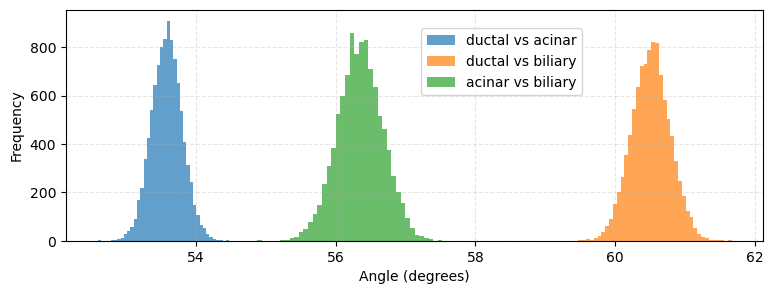

In [35]:
# visualize
plt.figure(figsize=(9, 3))
plt.grid(linestyle="--",alpha =.3)
for (a, b), vals in boot_angles.items():
    plt.hist(vals, bins=40, alpha=0.7, label=f"{a} vs {b}")

plt.xlabel("Angle (degrees)")
plt.ylabel("Frequency")
plt.legend(frameon=True, loc="upper right", bbox_to_anchor=(0.75, 0.95))

plt.show()

Developmental lineage directions defined relative to a foregut anchor are reproducibly separated by ~50–60°, with narrow bootstrap confidence intervals, indicating that the embedding captures a stable, multi-directional diversification of epithelial fates rather than a single linear trajectory.

1. The geometry is stable. These are not centroid accidents. If this were noisy: histograms would be wide, overlapping heavily
irregular shapes. Instead we have: narrow peaks (~±1–2° visually), reproducible separation.
 
2. The three lineages are distinct directions. Not just “different clusters,” but: different vectors from a shared anchor.
That’s a much stronger statement. Because: clustering = position difference, angles = directional organization. I now have evidence for the second.
 
3. The topology is **fan-like, not tree-like**. This is subtle but important.
I do not see: one small angle + one large angle (hierarchical split). I see: ~equal angles (~55–60°). That implies:
a multi-directional diversification rather than a strict binary bifurcation. So don’t force a tree narrative.

>Developmental cells occupied broad regions around each axis, consistent with a continuous and overlapping manifold rather than discrete trajectories

**Are those branch directions actually occupied by cells, instead of being just endpoint geometry?**

turning every cell into two numbers relative to each proposed branch:
- how far it goes along the branch --> t
- how far it sits away from the branch line --> d_perp

In [36]:
c_root = centroids["foregut"]

branch_data = {}
for term in ["ductal", "acinar", "biliary"]:
    t, d_perp, L, u = branch_coordinates(Xd_pca_sub, c_root, centroids[term])
    branch_data[term] = {
        "t": t,
        "d_perp": d_perp,
        "L": L,
        "u": u
    }

**df_branch[f"tfrac_{term}"]** below

This gives a normalized branch position:
- tfrac = 0 means near the root
- tfrac = 1 means near the terminal centroid
- 0 < tfrac < 1 means between root and terminal
- tfrac > 1 means beyond the terminal centroid
- tfrac < 0 means behind the root

This normalization is useful because ductal/acinar/biliary branches may have different lengths.\
So instead of comparing raw t, you compare everyone on the same 0-to-1 scale.

In [37]:
df_branch = pd.DataFrame({
    "label": labels_dev
})

for term in ["ductal", "acinar", "biliary"]:
    df_branch[f"t_{term}"] = branch_data[term]["t"]
    df_branch[f"d_{term}"] = branch_data[term]["d_perp"]
    df_branch[f"tfrac_{term}"] = branch_data[term]["t"] / (branch_data[term]["L"] + 1e-12)

df_branch

,label,t_ductal,d_ductal,tfrac_ductal,t_acinar,d_acinar,tfrac_acinar,t_biliary,d_biliary,tfrac_biliary
0,acinar,4.872038,14.272552,0.590667,8.321395,12.577631,0.946591,4.981018,14.234886,0.575974
1,acinar,4.648724,14.659842,0.563593,8.330552,12.927628,0.947633,4.366748,14.746292,0.504943
2,acinar,5.156587,14.319375,0.625164,8.408967,12.685584,0.956553,4.477133,14.546138,0.517708
3,acinar,4.950023,13.137042,0.600121,8.572419,11.117476,0.975146,9.071795,10.713875,1.049006
4,acinar,5.089495,14.068703,0.617030,4.853066,14.151999,0.552055,6.956080,13.245539,0.804358
...,...,...,...,...,...,...,...,...,...,...
13432,foregut,0.906988,13.527967,0.109960,0.448097,13.550931,0.050973,0.291977,13.555194,0.033762
13433,foregut,-0.390595,11.353769,-0.047354,-0.916610,11.323448,-0.104268,-0.514445,11.348833,-0.059487
13434,foregut,0.443421,12.648978,0.053759,0.642156,12.640447,0.073048,1.027229,12.614993,0.118782
13435,foregut,-1.670308,10.656375,-0.202502,-1.791004,10.636754,-0.203734,-2.321885,10.533618,-0.268488


*tfrac*, **Fig S7A**

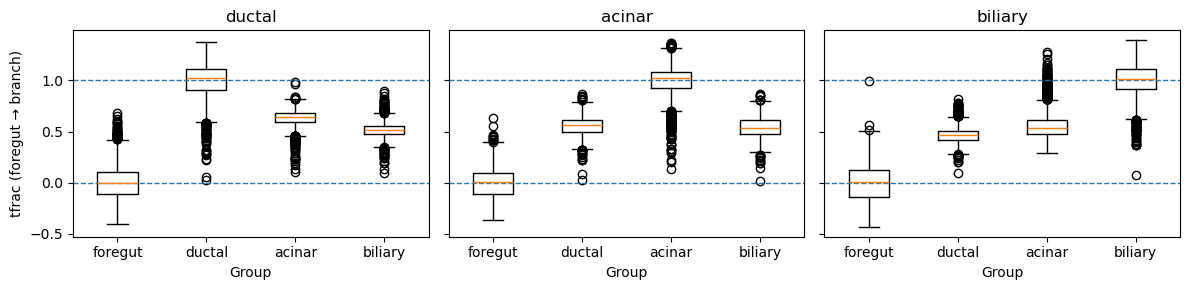

In [38]:
terms = ["ductal", "acinar", "biliary"]
groups = ["foregut", "ductal", "acinar", "biliary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)

for ax, term in zip(axes, terms):
    data = [
        df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
        for g in groups
    ]
    
    ax.boxplot(data, tick_labels=groups)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.axhline(1, linestyle="--", linewidth=1)
    
    ax.set_title(term)
    ax.set_xlabel("Group")

axes[0].set_ylabel("tfrac (foregut → branch)")

plt.tight_layout()
plt.show()

*d_perp*, **Fig S7B**

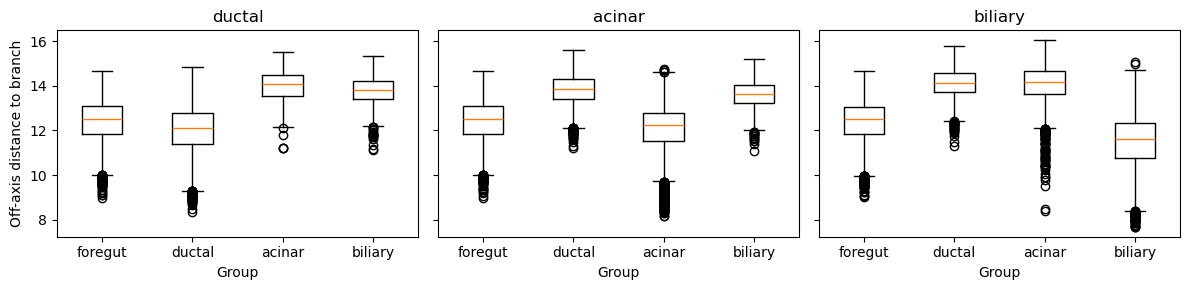

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)

for ax, term in zip(axes, terms):
    data = [
        df_branch.loc[df_branch["label"] == g, f"d_{term}"].values
        for g in groups
    ]
    
    ax.boxplot(data, tick_labels=groups)
    ax.set_title(term)
    ax.set_xlabel("Group")


axes[0].set_ylabel("Off-axis distance to branch")

plt.tight_layout()
plt.show()

Define branch **corridors**. A branch corridor should mean:
- cell lies between root and terminal
- cell is close to the axis

In [39]:
corridor_masks = {}

for term in ["ductal", "acinar", "biliary"]:
    tfrac = df_branch[f"tfrac_{term}"].values   # .. along branch
    d = df_branch[f"d_{term}"].values           # .. distance from branch 
    
    # between root and terminal, with a little slack
    in_longitudinal_range = (tfrac >= 0.0) & (tfrac <= 1.0)
    
    # close to axis: choose a percentile threshold
    d_thresh = np.quantile(d[in_longitudinal_range], 0.25)
    near_axis = d <= d_thresh
    
    corridor_masks[term] = in_longitudinal_range & near_axis
    print(term, "corridor size:", corridor_masks[term].sum(),"d_thresh:", d_thresh)
    print(term, "total:",np.sum(df_branch["label"]== term))

ductal corridor size: 2305 d_thresh: 12.972501754760742
ductal total: 4000
acinar corridor size: 2349 d_thresh: 12.88028621673584
acinar total: 3747
biliary corridor size: 2641 d_thresh: 13.1626558303833
biliary total: 1742


In [40]:
for a in ["ductal", "acinar", "biliary"]:
    for b in ["ductal", "acinar", "biliary"]:
        if a < b:
            overlap = (corridor_masks[a] & corridor_masks[b]).sum()
            print(a, b, "overlap:", overlap)

acinar ductal overlap: 952
acinar biliary overlap: 1244
biliary ductal overlap: 1111


Define **candidate intermediates**. For a given branch, a candidate intermediate should be:
- not too close to root
- not too close to terminal
- inside corridor

In [41]:
# Which biological labels occupy this transition zone?
intermediate_masks = {}

for term in ["ductal", "acinar", "biliary"]:
    tfrac = df_branch[f"tfrac_{term}"].values
    # .. middle of the branch
    in_middle = (tfrac >= 0.2) & (tfrac <= 0.8)
    intermediate_masks[term] = corridor_masks[term] & in_middle
    
    print(term, "candidate intermediates:", intermediate_masks[term].sum())
    print(df_branch.loc[intermediate_masks[term], "label"].value_counts())

ductal candidate intermediates: 610
label
acinar     199
foregut    169
biliary    128
ductal     114
Name: count, dtype: int64
acinar candidate intermediates: 749
label
ductal     350
biliary    205
acinar      99
foregut     95
Name: count, dtype: int64
biliary candidate intermediates: 968
label
ductal     331
foregut    318
acinar     188
biliary    131
Name: count, dtype: int64


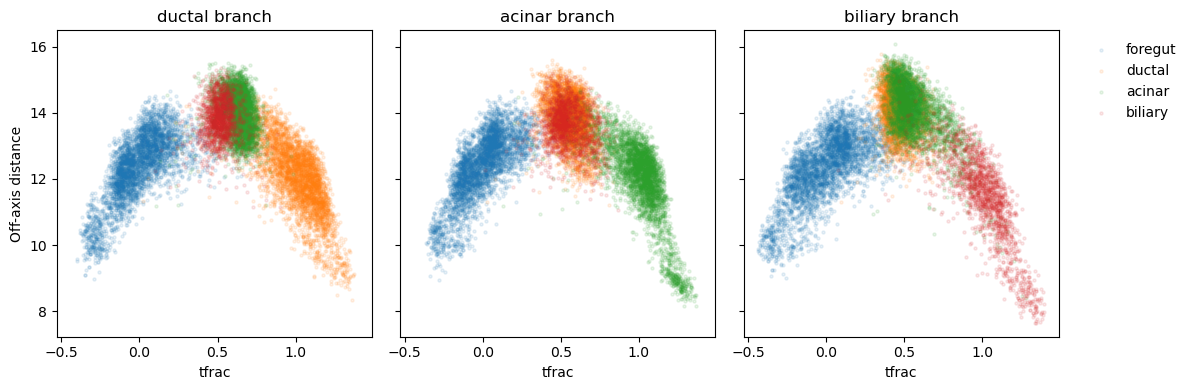

In [42]:
terms = ["ductal", "acinar", "biliary"]
plot_groups = ["foregut", "ductal", "acinar", "biliary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, sharex=True)

for ax, term in zip(axes, terms):
    
    for g in plot_groups:
        m = df_branch["label"].values == g
        
        ax.scatter(
            df_branch.loc[m, f"tfrac_{term}"],
            df_branch.loc[m, f"d_{term}"],
            s=5,
            alpha=0.1,
            label=g
        )
    
    ax.set_title(term +" branch")
    ax.set_xlabel("tfrac")

axes[0].set_ylabel("Off-axis distance")

# show legend only once (otherwise it's cluttered)
axes[-1].legend(frameon=False, bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

Note: the developmental trajectories are **curved**, but I am modeling them as straight lines.

Quantify branch selectivity
For each branch, ask: which label is closest to that branch?

In [43]:
for term in ["ductal", "acinar", "biliary"]:
    print(f"\nBranch: foregut→{term}")
    print(
        df_branch.groupby("label")[f"d_{term}"]
        .median()
        .sort_values()
    )


Branch: foregut→ductal
label
ductal     12.114468
foregut    12.515536
biliary    13.822948
acinar     14.072251
Name: d_ductal, dtype: float32

Branch: foregut→acinar
label
acinar     12.224310
foregut    12.528912
biliary    13.647119
ductal     13.877138
Name: d_acinar, dtype: float32

Branch: foregut→biliary
label
biliary    11.632795
foregut    12.498041
ductal     14.138264
acinar     14.155651
Name: d_biliary, dtype: float32


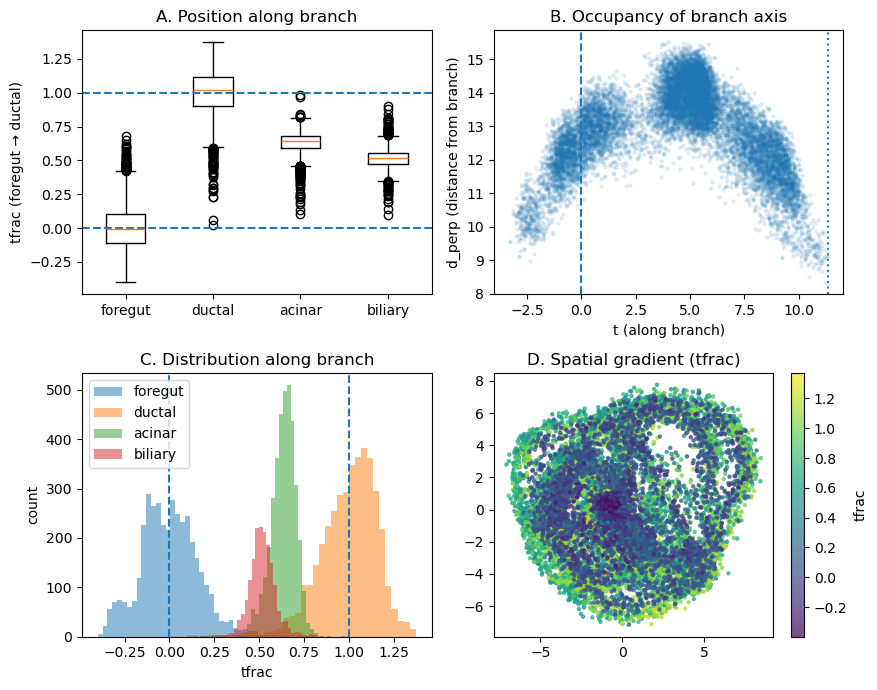

In [44]:
term = "ductal"
groups = ["foregut", "ductal", "acinar", "biliary"]

fig, axes = plt.subplots(2, 2, figsize=(9, 7))

# =========================
# PANEL A — boxplot (your original idea)
# =========================
data = [
    df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    for g in groups
]

axes[0, 0].boxplot(data, tick_labels=groups)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].axhline(1, linestyle="--")
axes[0, 0].set_ylabel(f"tfrac (foregut → {term})")
axes[0, 0].set_title("A. Position along branch")

# =========================
# PANEL B — t vs d_perp
# =========================
t = df_branch[f"t_{term}"].values
d = df_branch[f"d_{term}"].values

axes[0, 1].scatter(t, d, s=5, alpha=0.1)
axes[0, 1].axvline(0, linestyle="--")
axes[0, 1].axvline(df_branch[f"t_{term}"].max(), linestyle=":")
axes[0, 1].set_xlabel("t (along branch)")
axes[0, 1].set_ylabel("d_perp (distance from branch)")
axes[0, 1].set_title("B. Occupancy of branch axis")

# =========================
# PANEL C — histogram of tfrac
# =========================
for g in groups:
    vals = df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    axes[1, 0].hist(vals, bins=40, alpha=0.5, label=g)

axes[1, 0].axvline(0, linestyle="--")
axes[1, 0].axvline(1, linestyle="--")
axes[1, 0].set_xlabel("tfrac")
axes[1, 0].set_ylabel("count")
axes[1, 0].set_title("C. Distribution along branch")
axes[1, 0].legend()

# =========================
# PANEL D — embedding colored by tfrac
# =========================
scat = axes[1, 1].scatter(
    Xd_pca_sub[:, 0],
    Xd_pca_sub[:, 1],
    c=df_branch[f"tfrac_{term}"].values,
    s=5,
    alpha=0.7
)

axes[1, 1].set_title("D. Spatial gradient (tfrac)")
plt.colorbar(scat, ax=axes[1, 1], label="tfrac")

plt.tight_layout()
plt.show()

comments of the figure above:
- A. if I project cells onto the foregut→ductal direction, ductal cells land further along that direction than foregut cells.
- B. cells are not close to the ductal axis: the axis is not acting like a populated tube; intermediate t values are actually among the furthest from the line
- C. the ductal direction captures one broad developmental ordering
- D. useful ordering axis, weak branch axis.

--> you found informative developmental directions, not strongly occupied straight branches.

The other two are similar

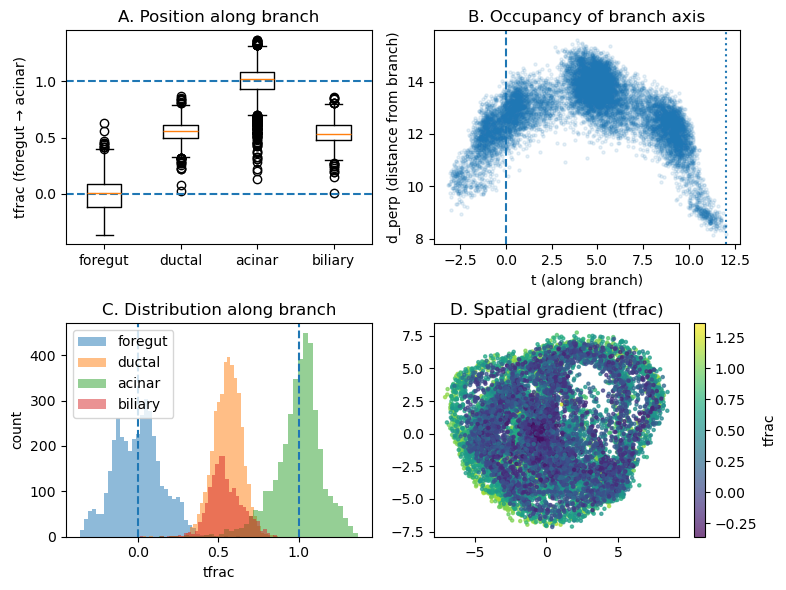

In [45]:
term = "acinar"
groups = ["foregut", "ductal", "acinar", "biliary"]

fig, axes = plt.subplots(2, 2, figsize=(8, 6))

# =========================
# PANEL A — boxplot (your original idea)
# =========================
data = [
    df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    for g in groups
]

axes[0, 0].boxplot(data, tick_labels=groups)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].axhline(1, linestyle="--")
axes[0, 0].set_ylabel(f"tfrac (foregut → {term})")
axes[0, 0].set_title("A. Position along branch")

# =========================
# PANEL B — t vs d_perp
# =========================
t = df_branch[f"t_{term}"].values
d = df_branch[f"d_{term}"].values

axes[0, 1].scatter(t, d, s=5, alpha=0.1)
axes[0, 1].axvline(0, linestyle="--")
axes[0, 1].axvline(df_branch[f"t_{term}"].max(), linestyle=":")
axes[0, 1].set_xlabel("t (along branch)")
axes[0, 1].set_ylabel("d_perp (distance from branch)")
axes[0, 1].set_title("B. Occupancy of branch axis")

# =========================
# PANEL C — histogram of tfrac
# =========================
for g in groups:
    vals = df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    axes[1, 0].hist(vals, bins=40, alpha=0.5, label=g)

axes[1, 0].axvline(0, linestyle="--")
axes[1, 0].axvline(1, linestyle="--")
axes[1, 0].set_xlabel("tfrac")
axes[1, 0].set_ylabel("count")
axes[1, 0].set_title("C. Distribution along branch")
axes[1, 0].legend()

# =========================
# PANEL D — embedding colored by tfrac
# =========================
scat = axes[1, 1].scatter(
    Xd_pca_sub[:, 0],
    Xd_pca_sub[:, 1],
    c=df_branch[f"tfrac_{term}"].values,
    s=5,
    alpha=0.7
)

axes[1, 1].set_title("D. Spatial gradient (tfrac)")
plt.colorbar(scat, ax=axes[1, 1], label="tfrac")

plt.tight_layout()
plt.show()

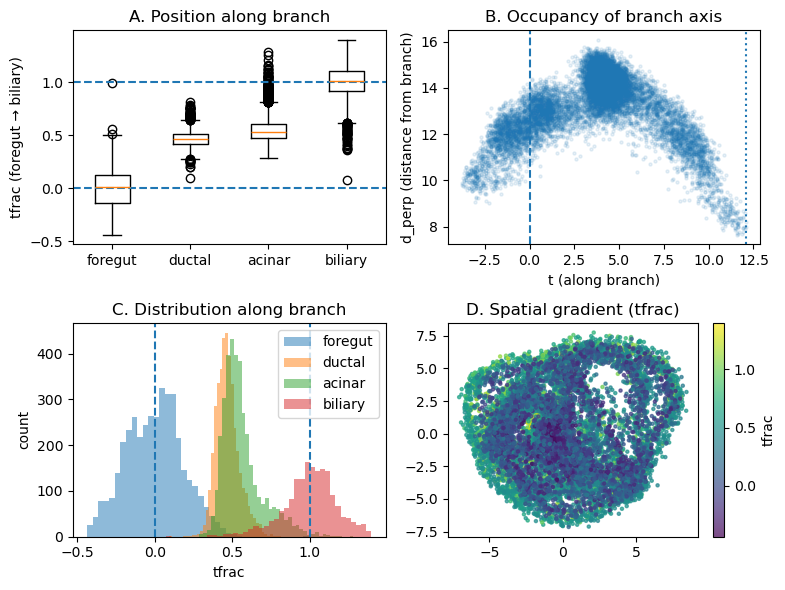

In [46]:
term = "biliary"
groups = ["foregut", "ductal", "acinar", "biliary"]

fig, axes = plt.subplots(2, 2, figsize=(8, 6))

# =========================
# PANEL A — boxplot (your original idea)
# =========================
data = [
    df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    for g in groups
]

axes[0, 0].boxplot(data, tick_labels=groups)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].axhline(1, linestyle="--")
axes[0, 0].set_ylabel(f"tfrac (foregut → {term})")
axes[0, 0].set_title("A. Position along branch")

# =========================
# PANEL B — t vs d_perp
# =========================
t = df_branch[f"t_{term}"].values
d = df_branch[f"d_{term}"].values

axes[0, 1].scatter(t, d, s=5, alpha=0.1)
axes[0, 1].axvline(0, linestyle="--")
axes[0, 1].axvline(df_branch[f"t_{term}"].max(), linestyle=":")
axes[0, 1].set_xlabel("t (along branch)")
axes[0, 1].set_ylabel("d_perp (distance from branch)")
axes[0, 1].set_title("B. Occupancy of branch axis")

# =========================
# PANEL C — histogram of tfrac
# =========================
for g in groups:
    vals = df_branch.loc[df_branch["label"] == g, f"tfrac_{term}"].values
    axes[1, 0].hist(vals, bins=40, alpha=0.5, label=g)

axes[1, 0].axvline(0, linestyle="--")
axes[1, 0].axvline(1, linestyle="--")
axes[1, 0].set_xlabel("tfrac")
axes[1, 0].set_ylabel("count")
axes[1, 0].set_title("C. Distribution along branch")
axes[1, 0].legend()

# =========================
# PANEL D — embedding colored by tfrac
# =========================
scat = axes[1, 1].scatter(
    Xd_pca_sub[:, 0],
    Xd_pca_sub[:, 1],
    c=df_branch[f"tfrac_{term}"].values,
    s=5,
    alpha=0.7
)

axes[1, 1].set_title("D. Spatial gradient (tfrac)")
plt.colorbar(scat, ax=axes[1, 1], label="tfrac")

plt.tight_layout()
plt.show()

**branch corridors SUMMARY**

Create a table per branch:
- number of cells in corridor
- number in middle corridor
- label composition in middle corridor
- median off-axis distance by label
- median branch position by label

In [47]:
summary_rows = []

for term in ["ductal", "acinar", "biliary"]:
    tfrac = df_branch[f"tfrac_{term}"].values
    d = df_branch[f"d_{term}"].values
    corr = corridor_masks[term]
    inter = intermediate_masks[term]
    
    row = {
        "branch": f"foregut_to_{term}",
        "n_corridor": int(corr.sum()),
        "n_intermediate": int(inter.sum()),
        "median_d_foregut": float(df_branch.loc[df_branch["label"]=="foregut", f"d_{term}"].median()),
        f"median_d_{term}": float(df_branch.loc[df_branch["label"]==term, f"d_{term}"].median()),
        "median_t_foregut": float(df_branch.loc[df_branch["label"]=="foregut", f"tfrac_{term}"].median()),
        f"median_t_{term}": float(df_branch.loc[df_branch["label"]==term, f"tfrac_{term}"].median()),
    }
    summary_rows.append(row)

summary_branch = pd.DataFrame(summary_rows)
summary_branch

,branch,n_corridor,n_intermediate,median_d_foregut,median_d_ductal,median_t_foregut,median_t_ductal,median_d_acinar,median_t_acinar,median_d_biliary,median_t_biliary
0,foregut_to_ductal,2305,610,12.515536,12.114468,-0.004523,1.019775,NaN,NaN,NaN,NaN
1,foregut_to_acinar,2349,749,12.528912,NaN,0.005387,NaN,12.22431,1.019443,NaN,NaN
2,foregut_to_biliary,2641,968,12.498041,NaN,0.008127,NaN,NaN,NaN,11.632795,1.011113


##### 1. There is genuine interior occupancy

The branch corridors contain substantial numbers of cells:

* foregut → ductal: (2305) corridor cells
* foregut → acinar: (2349) corridor cells
* foregut → biliary: (2641) corridor cells

Within these corridors, many cells occupy intermediate positions rather than lying near either endpoint:

* ductal branch: (610) candidate intermediates
* acinar branch: (749) candidate intermediates
* biliary branch: (968) candidate intermediates

So the lineage directions are not supported only by endpoint centroids. There are real cells distributed between the foregut anchor and the terminal states. This supports the interpretation that the developmental geometry has occupied root-to-terminal continua, not just centroid-defined lines.


##### 2. The ordering is correct

For each branch, the longitudinal coordinate behaves as expected:

* foregut cells have median (t_{\mathrm{frac}} \approx 0)
* the corresponding terminal population has median (t_{\mathrm{frac}} \approx 1)

Specifically:

* foregut → ductal: foregut median (t_{\mathrm{frac}} = -0.005), ductal median (t_{\mathrm{frac}} = 1.020)
* foregut → acinar: foregut median (t_{\mathrm{frac}} = 0.005), acinar median (t_{\mathrm{frac}} = 1.019)
* foregut → biliary: foregut median (t_{\mathrm{frac}} = 0.008), biliary median (t_{\mathrm{frac}} = 1.011)

This is important. It means the axes are correctly oriented and biologically interpretable: the projection coordinate genuinely tracks movement from the foregut reference state toward the appropriate terminal identity.


##### 3. The key caveat is weak branch confinement

The tension is in the orthogonal distances. The median off-axis distances are broadly similar for foregut and terminal populations:

* ductal branch: foregut median (d_{\perp} = 12.52), ductal median (d_{\perp} = 12.11)
* acinar branch: foregut median (d_{\perp} = 12.53), acinar median (d_{\perp} = 12.22)
* biliary branch: foregut median (d_{\perp} = 12.50), biliary median (d_{\perp} = 11.63)

So yes, the developmental space has distinct, stable lineage directions, and cells occupy positions along these directions. But the cells are not tightly confined to narrow, branch-specific trajectories. The off-axis distances remain large and comparable across root and terminal populations.



#### The best interpretation is therefore:

Developmental organization is **directionally structured but not sharply canalized**. The manifold contains reproducible lineage-oriented axes with meaningful root-to-terminal ordering, but branch selectivity is weak. Cells occupy a shared, broad developmental space rather than discrete, narrow lineage tubes.

In sort, the geometry shows:

•	distinct directions (angles)\
•	stable axes\
•	cells spread along axes

but:\
•	branch selectivity is weak

**Meaning:** Cells are not tightly confined to “their own” branch. Instead: The manifold looks like a shared low-dimensional space where directions exist, but boundaries are fuzzy.


*last check*

In [48]:
print("std Xd_pca_sub:",np.std(Xd_pca_sub)) 
print("mean Xd_pca_sub:", np.mean(np.linalg.norm(Xd_pca_sub, axis=1)))

std Xd_pca_sub: 1.5496557
mean Xd_pca_sub: 13.415746


What your scale tells us\
•	std ≈ 1.55\
•	mean norm ≈ 13.41

So your space is:\
•	reasonably isotropic (no explosion)\
•	distances ~10–15 are totally normal

That means your d_perp ≈ 11–12 is not a bug. It’s just the natural scale of your embedding. So we can trust the earlier interpretation.

---
---

>New geometric questions on **cancer cells**

- A. Are cancer cells closer to one branch than the others?   
- B. Are cancer cells farther off-axis than DEV cells?
- C. Do cancer cells extend beyond terminal developmental positions?

*cancer branch coordinates*

In [49]:
# .. same quantitites for the distances used before
c_root = centroids["foregut"]

cancer_branch = {}
for term in ["ductal", "acinar", "biliary"]:
    t, d_perp, L, u = branch_coordinates(Xc_pca, c_root, centroids[term])
    cancer_branch[term] = {
        "t": t,
        "d_perp": d_perp,
        "L": L,
        "u": u
    }

In [50]:
# .. dataframe
df_cancer_branch = pd.DataFrame(index=np.arange(Xc_pca.shape[0]))

# optional, if you have state labels
if "cancer_state" in A_cancer_aln.obs.columns:
    df_cancer_branch["cancer_state"] = A_cancer_aln.obs["cancer_state"].values
if "cluster" in A_cancer_aln.obs.columns:
    df_cancer_branch["cluster"] = A_cancer_aln.obs["cluster"].values

for term in ["ductal", "acinar", "biliary"]:
    df_cancer_branch[f"t_{term}"] = cancer_branch[term]["t"]
    df_cancer_branch[f"d_{term}"] = cancer_branch[term]["d_perp"]
    df_cancer_branch[f"tfrac_{term}"] = cancer_branch[term]["t"] / (cancer_branch[term]["L"] + 1e-12)

In [51]:
A_cancer_aln.obs["cancer_state"].values

['transitional', 'transitional', 'transitional', 'transitional', 'transitional', ..., 'ductal', 'ductal', 'ductal', 'ductal', 'ductal']
Length: 28131
Categories (3, object): ['ductal', 'malignant_ductal', 'transitional']

In [52]:
df_cancer_branch

,cancer_state,cluster,t_ductal,d_ductal,tfrac_ductal,t_acinar,d_acinar,tfrac_acinar,t_biliary,d_biliary,tfrac_biliary
0,transitional,0,5.906370,8.566985,0.716065,4.495972,9.384277,0.511434,4.916130,9.171155,0.568470
1,transitional,1,2.928420,9.835166,0.355030,3.271755,9.726344,0.372175,3.995218,9.452216,0.461982
2,transitional,1,3.222239,11.241759,0.390652,3.397321,11.190093,0.386458,3.791447,11.062771,0.438419
3,transitional,1,3.469100,9.122596,0.420580,4.116844,8.849182,0.468307,4.268833,8.776873,0.493621
4,transitional,5,4.797621,10.064515,0.581645,4.533161,10.186366,0.515665,3.929073,10.434272,0.454333
...,...,...,...,...,...,...,...,...,...,...,...
28126,ductal,2,4.733507,9.880048,0.573872,5.721574,9.342645,0.650851,3.400442,10.414338,0.393206
28127,ductal,2,4.285614,10.362453,0.519571,5.420589,9.816524,0.616613,3.519394,10.647102,0.406961
28128,ductal,9,1.367384,12.638254,0.165776,4.814298,11.765108,0.547645,3.655662,12.175030,0.422718
28129,ductal,2,4.095509,10.187237,0.496523,5.304900,9.613066,0.603453,3.186053,10.507238,0.368415


*Put dev and cancer into the same comparison table*

In [54]:
df_dev_branch = df_branch.copy()
df_dev_branch["dataset"] = "DEV"

df_cancer_branch["dataset"] = "CANCER"

# for consistent column names, DEV already has "label"
# make a generic state column
df_dev_branch["state"] = df_dev_branch["label"]

if "cancer_state" in df_cancer_branch.columns:
    df_cancer_branch["state"] = df_cancer_branch["cancer_state"]
elif "cluster" in df_cancer_branch.columns:
    df_cancer_branch["state"] = df_cancer_branch["cluster"]
else:
    df_cancer_branch["state"] = "cancer"

df_compare = pd.concat([df_dev_branch, df_cancer_branch],axis=0,ignore_index=True,sort=False)

**First-pass summaries**

*Median branch position and off-axis distance by dataset*

In [55]:
summary_compare = []

for term in ["ductal", "acinar", "biliary"]:
    for ds in ["DEV", "CANCER"]:
        sub = df_compare[df_compare["dataset"] == ds]
        summary_compare.append({
            "branch": term,
            "dataset": ds,
            "median_tfrac": float(sub[f"tfrac_{term}"].median()),
            "q25_tfrac": float(sub[f"tfrac_{term}"].quantile(0.25)),
            "q75_tfrac": float(sub[f"tfrac_{term}"].quantile(0.75)),
            "median_d": float(sub[f"d_{term}"].median()),
            "q25_d": float(sub[f"d_{term}"].quantile(0.25)),
            "q75_d": float(sub[f"d_{term}"].quantile(0.75)),
        })

summary_compare_df = pd.DataFrame(summary_compare)
summary_compare_df

,branch,dataset,median_tfrac,q25_tfrac,q75_tfrac,median_d,q25_d,q75_d
0,ductal,DEV,0.605287,0.158525,0.850789,13.063840,12.119555,13.873470
1,ductal,CANCER,0.466605,0.359235,0.567410,10.277833,9.770582,10.772590
2,acinar,DEV,0.547064,0.150749,0.815437,13.017640,12.191302,13.750319
3,acinar,CANCER,0.460249,0.377856,0.582441,10.089033,9.548793,10.738431
4,biliary,DEV,0.463616,0.183768,0.575633,13.513690,12.434570,14.271088
5,biliary,CANCER,0.406506,0.342282,0.481500,10.470827,9.924445,10.905713


*Fraction beyond the developmental endpoint*

In [56]:
endpoint_summary = []

for term in ["ductal", "acinar", "biliary"]:
    for ds in ["DEV", "CANCER"]:
        sub = df_compare[df_compare["dataset"] == ds]
        tfrac = sub[f"tfrac_{term}"].values
        endpoint_summary.append({
            "branch": term,
            "dataset": ds,
            "frac_below_0": float(np.mean(tfrac < 0)),
            "frac_0_to_1": float(np.mean((tfrac >= 0) & (tfrac <= 1))),
            "frac_above_1": float(np.mean(tfrac > 1)),
        })

endpoint_summary_df = pd.DataFrame(endpoint_summary)
endpoint_summary_df

,branch,dataset,frac_below_0,frac_0_to_1,frac_above_1
0,ductal,DEV,0.149215,0.686016,0.164769
1,ductal,CANCER,0.000071,0.999929,0.000000
2,acinar,DEV,0.143112,0.699040,0.157848
3,acinar,CANCER,0.000000,1.000000,0.000000
4,biliary,DEV,0.142294,0.785964,0.071742
5,biliary,CANCER,0.000000,1.000000,0.000000


*Closest branch per cancer cell*

In [57]:
dmat = np.vstack([df_cancer_branch["d_ductal"].values,df_cancer_branch["d_acinar"].values,df_cancer_branch["d_biliary"].values]).T

closest_idx = np.argmin(dmat, axis=1)
branch_names = np.array(["ductal", "acinar", "biliary"])

df_cancer_branch["closest_branch"] = branch_names[closest_idx]

df_cancer_branch["closest_branch"].value_counts(normalize=True)

closest_branch
acinar     0.412854
ductal     0.365824
biliary    0.221322
Name: proportion, dtype: float64

This tells you whether cancer preferentially aligns with one developmental axis.

In [58]:
pd.crosstab(df_cancer_branch["state"], df_cancer_branch["closest_branch"], normalize="index")

closest_branch,acinar,biliary,ductal
state,,,
ductal,0.896729,0.103271,0.000000
malignant_ductal,0.169396,0.200678,0.629927
transitional,0.371355,0.283370,0.345275


**plots**

*DEV vs CANCER distribution of **tfrac** (how far along a developmental axis cells sit).*

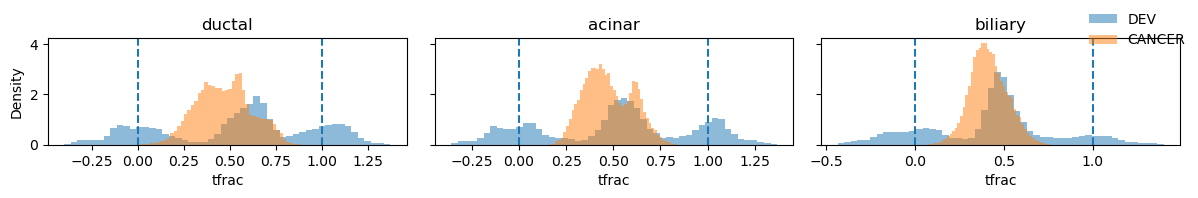

In [59]:
terms = ["ductal", "acinar", "biliary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 2), sharey=True)

for ax, term in zip(axes, terms):
    
    dev_vals = df_dev_branch[f"tfrac_{term}"].dropna().values
    can_vals = df_cancer_branch[f"tfrac_{term}"].dropna().values
    
    ax.hist(dev_vals, bins=50, alpha=0.5, label="DEV", density=True)
    ax.hist(can_vals, bins=50, alpha=0.5, label="CANCER", density=True)
    
    ax.axvline(0, linestyle="--")
    ax.axvline(1, linestyle="--")
    
    ax.set_title(term)
    ax.set_xlabel("tfrac")

# only one y-label to avoid clutter
axes[0].set_ylabel("Density")

# single shared legend (cleaner than 3 copies)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

*DEV vs CANCER distribution of **d_perp***

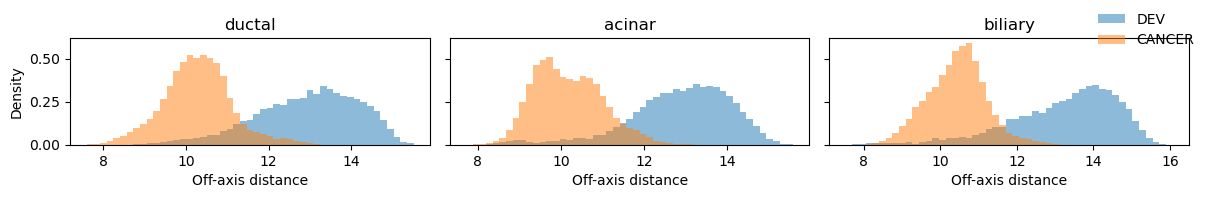

In [60]:
terms = ["ductal", "acinar", "biliary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 2), sharey=True)

for ax, term in zip(axes, terms):
    
    dev_vals = df_dev_branch[f"d_{term}"].dropna().values
    can_vals = df_cancer_branch[f"d_{term}"].dropna().values
    
    # optional: shared bins per panel for fair comparison
    all_vals = np.concatenate([dev_vals, can_vals])
    bins = np.linspace(all_vals.min(), all_vals.max(), 50)
    
    ax.hist(dev_vals, bins=bins, alpha=0.5, label="DEV", density=True)
    ax.hist(can_vals, bins=bins, alpha=0.5, label="CANCER", density=True)
    
    ax.set_title(term)
    ax.set_xlabel("Off-axis distance")

axes[0].set_ylabel("Density")

# shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

*cancer cells in branch-coordinate space*

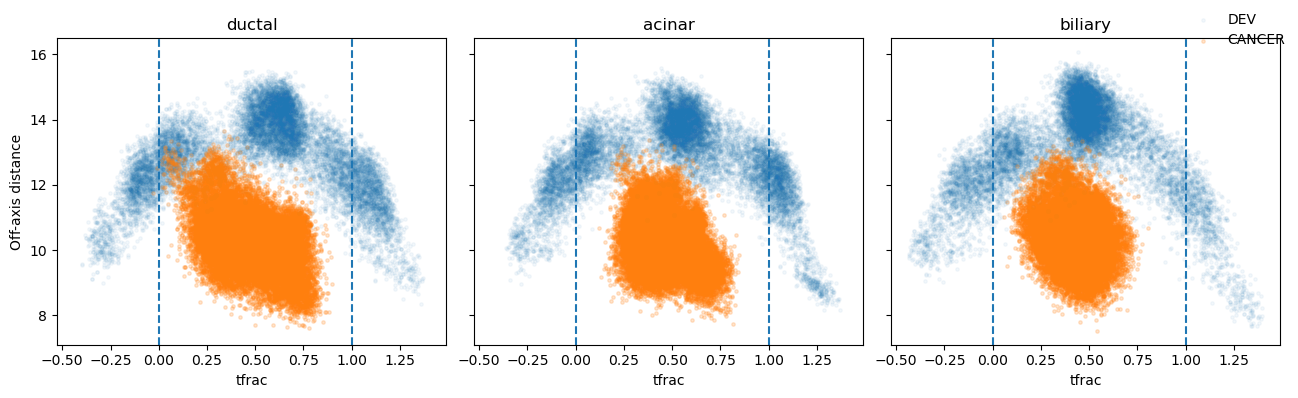

In [61]:
terms = ["ductal", "acinar", "biliary"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, sharex=True)

for ax, term in zip(axes, terms):
    
    # DEV
    ax.scatter(
        df_dev_branch[f"tfrac_{term}"],
        df_dev_branch[f"d_{term}"],
        s=6, alpha=0.05, label="DEV"
    )
    
    # CANCER
    ax.scatter(
        df_cancer_branch[f"tfrac_{term}"],
        df_cancer_branch[f"d_{term}"],
        s=6, alpha=0.2, label="CANCER"
    )
    
    ax.axvline(0, linestyle="--")
    ax.axvline(1, linestyle="--")
    
    ax.set_title(term)
    ax.set_xlabel("tfrac")

axes[0].set_ylabel("Off-axis distance")

# shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

**A simple developmental alignment score**

*Option A: nearest-branch distance*\
Smallest off-axis distance to any developmental branch:

In [62]:
df_cancer_branch["min_dev_axis_distance"] = np.min(dmat, axis=1)

*Option B: best longitudinal reuse*\
Max of branch positions:

In [63]:
tmat = np.vstack([
    df_cancer_branch["tfrac_ductal"].values,
    df_cancer_branch["tfrac_acinar"].values,
    df_cancer_branch["tfrac_biliary"].values
]).T

df_cancer_branch["max_dev_tfrac"] = np.max(tmat, axis=1)

In [64]:
df_cancer_branch

,cancer_state,cluster,t_ductal,d_ductal,tfrac_ductal,t_acinar,d_acinar,tfrac_acinar,t_biliary,d_biliary,tfrac_biliary,dataset,state,closest_branch,min_dev_axis_distance,max_dev_tfrac
0,transitional,0,5.906370,8.566985,0.716065,4.495972,9.384277,0.511434,4.916130,9.171155,0.568470,CANCER,transitional,ductal,8.566985,0.716065
1,transitional,1,2.928420,9.835166,0.355030,3.271755,9.726344,0.372175,3.995218,9.452216,0.461982,CANCER,transitional,biliary,9.452216,0.461982
2,transitional,1,3.222239,11.241759,0.390652,3.397321,11.190093,0.386458,3.791447,11.062771,0.438419,CANCER,transitional,biliary,11.062771,0.438419
3,transitional,1,3.469100,9.122596,0.420580,4.116844,8.849182,0.468307,4.268833,8.776873,0.493621,CANCER,transitional,biliary,8.776873,0.493621
4,transitional,5,4.797621,10.064515,0.581645,4.533161,10.186366,0.515665,3.929073,10.434272,0.454333,CANCER,transitional,ductal,10.064515,0.581645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28126,ductal,2,4.733507,9.880048,0.573872,5.721574,9.342645,0.650851,3.400442,10.414338,0.393206,CANCER,ductal,acinar,9.342645,0.650851
28127,ductal,2,4.285614,10.362453,0.519571,5.420589,9.816524,0.616613,3.519394,10.647102,0.406961,CANCER,ductal,acinar,9.816524,0.616613
28128,ductal,9,1.367384,12.638254,0.165776,4.814298,11.765108,0.547645,3.655662,12.175030,0.422718,CANCER,ductal,acinar,11.765108,0.547645
28129,ductal,2,4.095509,10.187237,0.496523,5.304900,9.613066,0.603453,3.186053,10.507238,0.368415,CANCER,ductal,acinar,9.613066,0.603453


In [65]:
# count of closest_branch per state
print('counts:')
counts = df_cancer_branch.value_counts(subset=['state', 'closest_branch']).unstack(fill_value=0)
print(counts)

# proportions (distribution) per state
print("")
print('proportions:')
proportions = counts.div(counts.sum(axis=1), axis=0)
print(proportions)



counts:
closest_branch    acinar  biliary  ductal
state                                    
ductal              5045      581       0
malignant_ductal    1500     1777    5578
transitional        5069     3868    4713

proportions:
closest_branch      acinar   biliary    ductal
state                                         
ductal            0.896729  0.103271  0.000000
malignant_ductal  0.169396  0.200678  0.629927
transitional      0.371355  0.283370  0.345275


>Malignant-state centroids

In [66]:
meta_cancer = A_cancer_aln.obs.copy()
labels_can = meta_cancer["cancer_state"].values
print(pd.Series(labels_can).value_counts())

transitional        13650
malignant_ductal     8855
ductal               5626
Name: count, dtype: int64


In [67]:
transitions = [
    ("ductal", "transitional"),
    ("transitional", "malignant_ductal"),
    ("ductal", "malignant_ductal"),
]

In [68]:
results = []

for s1, s2 in transitions:

    # malignant transitions on PC developmental space
    c1 = centroid_value(Xc_pca, labels_can, s1)
    c2 = centroid_value(Xc_pca, labels_can, s2)
    dv_pca = c2 - c1
    
    sims = {
        "ductal": cos_sim(dv_pca, vectors["ductal"]),
        "acinar": cos_sim(dv_pca, vectors["acinar"]),
        "biliary": cos_sim(dv_pca, vectors["biliary"]),
    }
    
    # .. developmental and residual decomposition, centroids in the CLS space
    c1 = centroid_value(Xc, labels_can, s1)
    c2 = centroid_value(Xc, labels_can, s2)
    dv_full = c2 - c1

    # ..
    v_proj = dv_full @ basis @ basis.T
    proj_norm = np.linalg.norm(v_proj)
    # ..
    v_res = dv_full - v_proj
    res_norm = np.linalg.norm(v_res)
    
    # ..
    results.append({
        "transition": f"{s1}→{s2}",
        "sim_ductal": sims["ductal"],
        "sim_acinar": sims["acinar"],
        "sim_biliary": sims["biliary"],
        "proj_norm": proj_norm,
        "res_norm": res_norm,
        "frac_explained": (proj_norm**2) / (proj_norm**2 + res_norm**2 + 1e-12),
        "residual_fraction": (res_norm**2) / (proj_norm**2 + res_norm**2 + 1e-12),
        "best_matching_branch": max(sims, key=sims.get),
    })

df_transition_results = pd.DataFrame(results)
df_transition_results

,transition,sim_ductal,sim_acinar,sim_biliary,proj_norm,res_norm,frac_explained,residual_fraction,best_matching_branch
0,ductal→transitional,0.007865,-0.249413,0.035476,6.267569,7.227996,0.429192,0.570808,biliary
1,transitional→malignant_ductal,0.175678,0.026297,0.095147,5.182854,4.146354,0.609748,0.390252,ductal
2,ductal→malignant_ductal,0.137273,-0.204080,0.102329,6.991948,7.721201,0.450557,0.549443,ductal


how internally consistent are cancer transitions?

In [69]:
c_duct = centroid_value(Xc_pca, labels_can, "ductal")
c_trans = centroid_value(Xc_pca, labels_can, "transitional")
c_malig = centroid_value(Xc_pca, labels_can, "malignant_ductal")

v1 = c_trans - c_duct
v2 = c_malig - c_trans
v3 = c_malig - c_duct

print("ductal->transitional vs transitional->malignant_ductal:", cos_sim(v1, v2))
print("ductal->transitional vs ductal->malignant_ductal:", cos_sim(v1, v3))
print("transitional->malignant_ductal vs ductal->malignant_ductal:", cos_sim(v2, v3))

ductal->transitional vs transitional->malignant_ductal: -0.2656244275110282
ductal->transitional vs ductal->malignant_ductal: 0.6995010706142131
transitional->malignant_ductal vs ductal->malignant_ductal: 0.5031551225515883


> ##### Even if cancer is not on developmental trajectories: could it still move between developmental states through continuous paths?

I am testing 3 competing models:
- Axis proximity model → cancer is just biased toward certain lineages
- Geodesic continuity model → cancer moves along curved paths within the developmental manifold
- Orthogonal transition model → cancer requires leaving the manifold

**Test 1** — **Axis proximity is not enough**
- Question: Are cancer cells “explained” just by being near developmental axes?

- Metric: Fraction of variance explained by projection onto axis span vs full dev subspace

In [70]:
# Full developmental-subspace projection of malignant cells
Xc_dev_recon = Xc @ basis @ basis.T
# projection
frac_dev = (np.linalg.norm(Xc_dev_recon, axis=1)**2/(np.linalg.norm(Xc, axis=1)**2 + 1e-12))

# Developmental lineage axes (vectors, defined above) in 75D PC-score space 
# Optional: normalize or not?
# For span projection, normalization is acceptable but not required.
# Normalization changes conditioning but not the span if vectors are nonzero. 
# shape: 75 x 3
A = np.stack(
    [vectors["ductal"] / (np.linalg.norm(vectors["ductal"]) + 1e-12),vectors["acinar"] / (np.linalg.norm(vectors["acinar"]) + 1e-12),
    vectors["biliary"] / (np.linalg.norm(vectors["biliary"]) + 1e-12),],axis=1)  

# this gives the same
# A = np.stack([vectors["ductal"], vectors["acinar"], vectors["biliary"]],axis=1) 


# Project malignant cells onto lineage-axis span
Xc_rel = Xc_pca - centroids["foregut"] # foregut relative coordinated systems
# project on the linear spam
Xc_axes_rel = Xc_rel @ A @ np.linalg.pinv(A)
frac_axes_given_dev = (np.linalg.norm(Xc_axes_rel, axis=1)**2/(np.linalg.norm(Xc_rel, axis=1)**2 + 1e-12))

print("Mean fraction in full developmental subspace:", frac_dev.mean())
print("Mean fraction of developmental-coordinate displacement captured by axes:",
      frac_axes_given_dev.mean())

Mean fraction in full developmental subspace: 0.40418708
Mean fraction of developmental-coordinate displacement captured by axes: 0.21577494


**TEST 2** — **Malignant transitions are only partially developmental**
- Question: Do cancer transitions lie within the developmental subspace?

In [71]:
results = []
desired_transitions = [
    ("ductal", "transitional"),
    ("transitional", "malignant_ductal"),
    ("ductal", "malignant_ductal"),
]

#for (s1, s2) in combinations(centroids_can.keys(), 2):
for (s1, s2) in desired_transitions:
    v = centroid_value(Xc, labels_can, s2) - centroid_value(Xc, labels_can, s1)

    # project onto dev subspace
    # turn the v  1D vector first into a row vector (1,256) v[None, :]
    # Why [0]? To convert the (1,256) row vector back to a 1D vector of length 256 for easier use (shape (256,)). 
    v_dev = (v[None, :] @ basis @ basis.T)[0]
    v_res = v - v_dev
    frac_dev = np.linalg.norm(v_dev)**2 / (np.linalg.norm(v)**2 + 1e-12)

    # include cosine computations here to be used in Fig.2
    # vectors in developmental space
    v_pca = centroid_value(Xc_pca, labels_can, s2) - centroid_value(Xc_pca, labels_can, s1)
    cosines = {k: cos_sim(v_pca, a) for k, a in vectors.items()}

    results.append({"transition": f"{s1}→{s2}","frac_dev": frac_dev,"residual_frac": 1 - frac_dev,**cosines})
    
df_transitions = pd.DataFrame(results)
df_transitions

,transition,frac_dev,residual_frac,ductal,acinar,biliary
0,ductal→transitional,0.429192,0.570808,0.007865,-0.249413,0.035476
1,transitional→malignant_ductal,0.609748,0.390252,0.175678,0.026297,0.095147
2,ductal→malignant_ductal,0.450557,0.549443,0.137273,-0.204080,0.102329


**TEST 3** — **Transitional states are not geodesic intermediates**

This is the subtle one—and very important.
- Question: Does the transitional state lie between endpoints in developmental space?

**Equivalent version in PC-score space**:
Because the projected centroids lie in the developmental PCA subspace, you can do this more simply in 75D PC-score space:

In [72]:
#Xc_pca = Xc @ B_dev_basis, or pca.transform(Xc_centered)

D_pc = centroid_value(Xc_pca, labels_can, "ductal")
M_pc = centroid_value(Xc_pca, labels_can, "malignant_ductal")
T_pc = centroid_value(Xc_pca, labels_can, "transitional")

DM = M_pc - D_pc
DT = T_pc - D_pc

t = np.dot(DT, DM) / (np.dot(DM, DM) + 1e-12)
P = D_pc + t * DM
dist_to_line = np.linalg.norm(T_pc - P)

line_len = np.linalg.norm(DM)
relative_dist = dist_to_line / (line_len + 1e-12)

cos_angle = np.dot(DT, DM) / (
    (np.linalg.norm(DT) * np.linalg.norm(DM)) + 1e-12
)
angle_deg = np.degrees(np.arccos(np.clip(cos_angle, -1, 1)))

print("Position along D->M:", t)
print("Distance to line:", dist_to_line)
print("D->M length:", line_len)
print("Relative distance:", relative_dist)
print("Angle D->T vs D->M:", angle_deg)

Position along D->M: 0.6270311904774039
Distance to line: 4.478999
D->M length: 6.9919457
Relative distance: 0.6405940924245153
Angle D->T vs D->M: 45.61301147968205


>### Figures

**Figure 2**

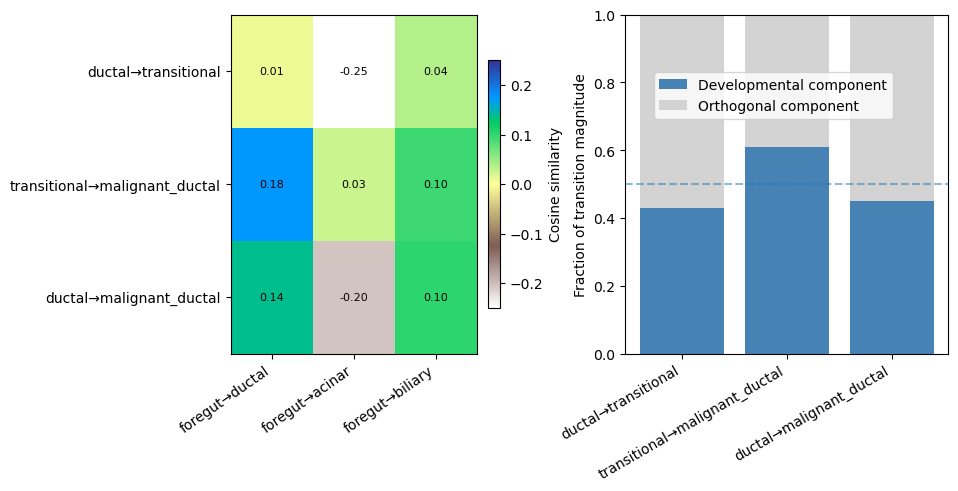

In [73]:
# transitions
frac_df = df_transitions[["transition","frac_dev","residual_frac","ductal","acinar","biliary"]].copy()

# In case I already saved long-format cosines, load them.
# Otherwise reconstruct from frac_df.
try:
    cos_df = pd.read_csv("transition_vs_dev_cosines.csv").copy()
except FileNotFoundError:
    cos_df = frac_df.melt(
        id_vars=["transition", "frac_dev", "residual_frac"],
        value_vars=["ductal", "acinar", "biliary"],
        var_name="dev_transition",
        value_name="cosine"
    ).rename(columns={"transition": "cancer_transition"})

# -----------------------------
# Standardize labels/order
# -----------------------------
transition_order = list(frac_df["transition"])

dev_label_map = {
    "ductal": "foregut→ductal",
    "acinar": "foregut→acinar",
    "biliary": "foregut→biliary",
    "foregut->ductal": "foregut→ductal",
    "foregut->acinar": "foregut→acinar",
    "foregut->biliary": "foregut→biliary",
}

cos_df["dev_transition"] = cos_df["dev_transition"].replace(dev_label_map)
dev_order = ["foregut→ductal", "foregut→acinar", "foregut→biliary"]

# Standardize cancer transition column name
if "cancer_transition" not in cos_df.columns and "transition" in cos_df.columns:
    cos_df = cos_df.rename(columns={"transition": "cancer_transition"})

# -----------------------------
# Panel A: Heatmap of cosine similarity
# -----------------------------
heat = (
    cos_df.pivot(index="cancer_transition", columns="dev_transition", values="cosine")
    .reindex(index=transition_order, columns=dev_order)
)

# -----------------------------
# Panel B: dev vs orthogonal fractions
# -----------------------------
frac_plot = frac_df.set_index("transition").reindex(transition_order).reset_index()

# -----------------------------
# Panel C: max absolute cosine by transition
# clearer than scatter for n=3
# -----------------------------
max_cos = (
    cos_df.groupby("cancer_transition")["cosine"]
    .apply(lambda x: np.max(np.abs(x)))
    .rename("max_abs_cosine")
    .reset_index()
)

summary = frac_plot.merge(
    max_cos,
    left_on="transition",
    right_on="cancer_transition",
    how="left"
)

# -----------------------------
# Build figure
# -----------------------------
fig = plt.figure(figsize=(14, 4.4))
gs = GridSpec(1, 3, width_ratios=[1.0, 1.2, 0.9], wspace=0.45)

# =============================
# Panel A — cosine heatmap
# =============================
ax1 = fig.add_subplot(gs[0, 0])

im = ax1.imshow(heat.values, aspect="auto", vmin=-0.25, vmax=0.25,cmap="terrain_r")



ax1.set_xticks(range(len(heat.columns)))
ax1.set_xticklabels(heat.columns, rotation=35, ha="right")
ax1.set_yticks(range(len(heat.index)))
ax1.set_yticklabels(heat.index)
#ax1.set_title("A. Weak alignment to developmental directions", fontsize=12)

cbar = plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label("Cosine similarity")

# Optional cell text
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat.iloc[i, j]
        if pd.notna(val):
            ax1.text(j, i, f"{val:.02f}", ha="center", va="center", fontsize=8)

# =============================
# Panel B — stacked fractions
# =============================
ax2 = fig.add_subplot(gs[0, 1])

x = np.arange(len(frac_plot))

ax2.bar(x, frac_plot["frac_dev"], label="Developmental component",color="steelblue")
ax2.bar(x,frac_plot["residual_frac"],bottom=frac_plot["frac_dev"],label="Orthogonal component",color="lightgray")

ax2.set_xticks(x)
ax2.set_xticklabels(frac_plot["transition"], rotation=30, ha="right")
ax2.set_ylabel("Fraction of transition magnitude")
ax2.set_ylim(0, 1.0)
#ax2.set_title("B. Transition magnitude is dominated by orthogonal structure", fontsize=12)
ax2.legend(frameon=True, loc="upper right", bbox_to_anchor=(0.85, 0.85))

# Optional dashed reference
ax2.axhline(0.5, linestyle="--", alpha=0.5)

#plt.tight_layout()
plt.show()

**Figure 3**

In [74]:
# 1) cluster_axis_alignment.csv
cluster_rows = []
foregut = centroids["foregut"]
centroids_can = compute_centroids(Xc_pca, labels_can)

for cluster_name, cvec in centroids_can.items():
    rel_vec = cvec - foregut
    row = {"cluster": cluster_name}
    for axis_name, axis_vec in vectors.items():
        row[axis_name] = cos_sim(rel_vec, axis_vec)
    cluster_rows.append(row)

align_df = pd.DataFrame(cluster_rows)

# 3) geodesic_deviation.csv
geo_df = pd.DataFrame([{
    "transition": "ductal->transitional->malignant_ductal",
    "projected_intermediate_score": 0.493080701552354,
    "fullspace_geodesic_deviation": 1.7930855
}])


In [75]:
#axis_cols = ["foregut_to_ductal", "foregut_to_acinar", "foregut_to_biliary"]
axis_cols = ["ductal", "acinar", "biliary"]
axis_labels = ["foregut→ductal", "foregut→acinar", "foregut→biliary"]

# -----------------------------
# Normalize Panel A
# -----------------------------
align_plot = align_df.copy()
align_plot[axis_cols] = align_plot[axis_cols].div(align_plot[axis_cols].sum(axis=1), axis=0)

# -----------------------------
# Select triplet
# -----------------------------
centroids_CLS_can = compute_centroids(Xc, labels_can)
D = centroids_CLS_can["ductal"]
T = centroids_CLS_can["transitional"]
M = centroids_CLS_can["malignant_ductal"]


# -----------------------------
# Developmental-space geometry for Panel C
# -----------------------------
# project all into dev subspace
D_dev = (D[None, :] @ basis @ basis.T) [0] 
M_dev = (M[None, :] @ basis @ basis.T) [0] 
T_dev = (T[None, :] @ basis @ basis.T) [0] 

DM = M_dev - D_dev
DT = T_dev - D_dev

DM_len = np.linalg.norm(DM) + 1e-12

# scalar position of T along the A->B line
t = np.dot(DT, DM) / (DM_len**2)

# closest point to T on the A->B line
P_dev = D_dev + t * DM

# perpendicular distance from T to the line
dist_to_line = np.linalg.norm(T_dev - P_dev)

# normalize off-path distance by endpoint separation
d_rel = dist_to_line / DM_len



- Position along D->M: 0.6270311904774039
- Distance to line: 4.478999
- D->M length: 6.9919457
- Relative distance: 0.6405940924245153
- Angle D->T vs D->M: 45.61301147968205

In [76]:
print("Position along D->M:", t)
print("Distance to line:", dist_to_line)
print("D->M length:", DM_len)
print("Relative distance:", d_rel)


Position along D->M: 0.6270310944300709
Distance to line: 4.479003
D->M length: 6.991947650910424
Relative distance: 0.6405944632598145


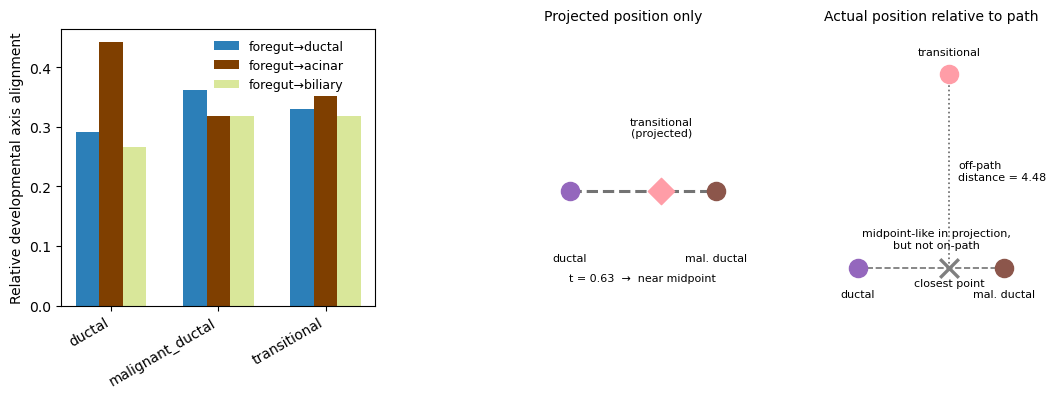

In [77]:
# -----------------------------
# Build figure
# -----------------------------
fig = plt.figure(figsize=(12.5, 3.6))
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.55], wspace=0.42)

# =============================
# Panel A
# =============================
ax1 = fig.add_subplot(gs[0, 0])
#panelA_colors = ["#4C78A8", "#59A14F", "#E15759"] 
panelA_colors = ["#2c7fb8", "#7f3f00", "#d9e79a"]
x = np.arange(len(align_plot))
width = 0.22

for i, col in enumerate(axis_cols):
    ax1.bar(x + i * width, align_plot[col], width=width, label=axis_labels[i],color=panelA_colors[i])

ax1.set_xticks(x + width)
ax1.set_xticklabels(align_plot["cluster"], rotation=30, ha="right")
ax1.set_ylabel("Relative developmental axis alignment")
#ax1.set_title("A", loc="left", fontweight="bold", fontsize=12)
ax1.legend(frameon=False, loc="upper left",bbox_to_anchor=(0.45, 1),fontsize = 9)

# =============================
# Panel B
# =============================
subgs = gs[0, 1].subgridspec(1, 2, wspace=0.45)

# Colors

cA = "#9467BD"   # ductal # purple
cB = "#8C564B"   # malignant_ductal # brown
cT = "#FF9DA7"   # transitional # pink
cP = "#7F7F7F"   # projected/closest-point marker # gray

# ------------------------------------------------------------------
# Panel B-left: projected position only
# ------------------------------------------------------------------
ax3a = fig.add_subplot(subgs[0, 0])

A_plot = np.array([0.0, 0.0])
B_plot = np.array([1.0, 0.0])
Tproj_plot = np.array([t, 0.0])

# endpoint path
ax3a.plot([A_plot[0], B_plot[0]], [0, 0], linestyle="--", linewidth=2.2, color="0.45")

# endpoints + projected transitional position
ax3a.scatter(*A_plot, s=170, color=cA, zorder=3)
ax3a.scatter(*B_plot, s=170, color=cB, zorder=3)
ax3a.scatter(*Tproj_plot, s=180, color=cT, marker="D", zorder=4)

# labels
ax3a.text(A_plot[0], -0.13, "ductal", ha="center", va="top", fontsize=8)
ax3a.text(B_plot[0], -0.13, "mal. ductal", ha="center", va="top", fontsize=8)
ax3a.text(Tproj_plot[0], 0.11, "transitional\n(projected)", ha="center", va="bottom", fontsize=8)

# title + annotation
ax3a.set_title("Projected position only", loc="left", fontsize=10)
ax3a.text(
    0.5, 0.08,
    f"t = {t:.2f}  \u2192  near midpoint",
    transform=ax3a.transAxes,
    ha="center", va="bottom", fontsize=8
)

# formatting
ax3a.set_xlim(-0.18, 1.18)
ax3a.set_ylim(-0.24, 0.34)
ax3a.set_xticks([])
ax3a.set_yticks([])
for spine in ax3a.spines.values():
    spine.set_visible(False)

# ------------------------------------------------------------------
# Panel B-right: actual position relative to the path
# ------------------------------------------------------------------
ax3b = fig.add_subplot(subgs[0, 1])

A_geom = np.array([0.0, 0.0])
B_geom = np.array([1.0, 0.0])
P_geom = np.array([t, 0.0])      # closest point on the path
T_geom = np.array([t, d_rel])    # actual transitional position

# path between endpoints
ax3b.plot([A_geom[0], B_geom[0]], [0, 0], linestyle="--", linewidth=1.2, color="0.45")

# perpendicular off-path deviation
ax3b.plot(
    [P_geom[0], T_geom[0]],
    [P_geom[1], T_geom[1]],
    linestyle=":",
    linewidth=1.2,
    color="0.4"
)

# points
ax3b.scatter(*A_geom, s=170, color=cA, zorder=3)
ax3b.scatter(*B_geom, s=170, color=cB, zorder=3)
ax3b.scatter(*T_geom, s=170, color=cT, zorder=4)
ax3b.scatter(*P_geom, s=180, marker="x", color=cP, linewidths=2.4, zorder=5)

# labels
ax3b.text(A_geom[0], -0.10 * max(d_rel, 0.7), "ductal", ha="center", va="top", fontsize=8)
ax3b.text(B_geom[0], -0.10 * max(d_rel, 0.7), "mal. ductal", ha="center", va="top", fontsize=8)
ax3b.text(T_geom[0], T_geom[1] + 0.08 * max(d_rel, 0.7), "transitional", ha="center", va="bottom", fontsize=8)
ax3b.text(P_geom[0], -0.05 * max(d_rel, 0.7), "closest point", ha="center", va="top", fontsize=8)

# annotate distance
ax3b.text(
    T_geom[0] + 0.06,
    T_geom[1] / 2,
    f"off-path\ndistance = {dist_to_line:.2f}",
    ha="left", va="center", fontsize=8
)

# title + interpretation
ax3b.set_title("Actual position relative to path", fontsize=10)
ax3b.text(
    0.53, 0.2,
    "midpoint-like in projection,\nbut not on-path",
    transform=ax3b.transAxes,
    ha="center", va="bottom", fontsize=8
)

# formatting
ypad = 0.18 * max(d_rel, 0.7)
ax3b.set_xlim(-0.18, 1.18)
ax3b.set_ylim(-ypad, d_rel + 1.2 * ypad)
ax3b.set_xticks([])
ax3b.set_yticks([])

#for spine in ["top", "right"]:
#    ax3b.spines[spine].set_visible(False)
# remove full frame
for spine in ax3b.spines.values():
    spine.set_visible(False)

plt.show()